# Week 03 — YCB-V Object Classification I

**Group 1 | Main Quest: Improving Deep Neural Networks**  
**Side Quest: Object Classification I**

Goal of this notebook:

- reuse the lightweight **YCB-V BOP'19 subset** from Weeks 1–2,
- select a small set of object classes,
- convert object annotations into cropped RGB classification samples,
- split the data by **scene** into train / validation / test,
- train a simple **MLP baseline**,
- evaluate it and save the Week 3 evidence.

> The baseline intentionally contains **no convolutional layers**. CNN classification is reserved for the later CNN weeks in the program.

## 0. Main Quest notes

Write only the concepts from **Improving Deep Neural Networks** that you actually studied this week.

Suggested connections to this notebook:

- train / validation / test sets,
- overfitting and generalization,
- learning rate,
- mini-batches,
- optimization,
- regularization as a **next-week** improvement.

> **My notes:**  
> ...

## 1. Install and import

The notebook uses PyTorch for the baseline model, scikit-learn for evaluation, and the same BOP/Hugging Face dataset source used previously.

In [1]:
%pip -q install huggingface_hub pillow matplotlib pandas scikit-learn torch torchvision

In [2]:
from pathlib import Path
import json
import random
import math
import zipfile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from huggingface_hub import hf_hub_download

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 2. Configuration

The defaults are intentionally small enough for a normal laptop.

- `N_CLASSES = 5`: selected object classes.
- `IMAGE_SIZE = 64`: each crop becomes a 64×64 RGB image.
- The per-class caps keep training time reasonable.
- There is **no augmentation** and **no regularization** in Week 3; those belong to Week 4 experiments.

In [3]:
DATASETS_DIR = Path("datasets")
DOWNLOAD_DIR = DATASETS_DIR / "downloads"
DATASET_ROOT = DATASETS_DIR / "ycbv"
OUTPUT_DIR = Path("outputs/week03")

N_CLASSES = 5
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 12
LEARNING_RATE = 1e-3

MIN_VISIBILITY = 0.35
MIN_BOX_SIDE = 24

MAX_TRAIN_PER_CLASS = 600
MAX_VAL_PER_CLASS = 150
MAX_TEST_PER_CLASS = 150

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
DATASET_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset root:", DATASET_ROOT.resolve())
print("Output dir:", OUTPUT_DIR.resolve())

Dataset root: /content/datasets/ycbv
Output dir: /content/outputs/week03


## 3. Download / reuse the YCB-V BOP subset

If the dataset is already present from Week 1 or Week 2, extraction is skipped.

The code downloads:

- `ycbv_base.zip`
- `ycbv_test_bop19.zip`

This is the lightweight BOP subset used in the previous weeks, not the full original YCB-Video archive.

In [4]:
REPO_ID = "bop-benchmark/ycbv"

def download_hf(filename):
    try:
        return Path(hf_hub_download(
            repo_id=REPO_ID,
            filename=filename,
            repo_type="dataset"
        ))
    except Exception:
        return Path(hf_hub_download(
            repo_id=REPO_ID,
            filename=filename
        ))

def extract_if_needed(zip_path, target_dir):
    marker = target_dir / ".week03_extracted"
    if marker.exists():
        return

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(target_dir)

def dataset_ready(root):
    test_dir = root / "test"
    return test_dir.exists() and any(test_dir.iterdir())

if not dataset_ready(DATASET_ROOT):
    base_zip = download_hf("ycbv_base.zip")
    test_zip = download_hf("ycbv_test_bop19.zip")

    print("Extracting base archive...")
    with zipfile.ZipFile(base_zip, "r") as zf:
        zf.extractall(DATASET_ROOT)

    print("Extracting BOP'19 test subset...")
    with zipfile.ZipFile(test_zip, "r") as zf:
        zf.extractall(DATASET_ROOT)
else:
    print("Dataset already exists. Download skipped.")

print("Ready:", dataset_ready(DATASET_ROOT))

ycbv_base.zip: reconstructing file:   0%|          |  0.00B / 15.8kB            

ycbv_base.zip: downloading bytes:           |  0.00B            

ycbv_test_bop19.zip: reconstructing file:   0%|          |  0.00B /  660MB            

ycbv_test_bop19.zip: downloading bytes:           |  0.00B            

Extracting base archive...
Extracting BOP'19 test subset...
Ready: True


## 4. Build an object-instance table

Each BOP scene has:

- RGB images,
- `scene_gt.json` with object IDs,
- `scene_gt_info.json` with bounding boxes and visibility.

Every annotated object instance becomes one possible classification sample.

Low-visibility objects and very tiny boxes are filtered because they are poor baseline-classification examples.

In [5]:
YCBV_OBJECTS = {
    1: "master_chef_can",
    2: "cracker_box",
    3: "sugar_box",
    4: "tomato_soup_can",
    5: "mustard_bottle",
    6: "tuna_fish_can",
    7: "pudding_box",
    8: "gelatin_box",
    9: "potted_meat_can",
    10: "banana",
    11: "pitcher_base",
    12: "bleach_cleanser",
    13: "bowl",
    14: "mug",
    15: "power_drill",
    16: "wood_block",
    17: "scissors",
    18: "large_marker",
    19: "large_clamp",
    20: "extra_large_clamp",
    21: "foam_brick",
}

def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def build_instance_table(dataset_root):
    test_root = dataset_root / "test"
    rows = []

    scene_dirs = sorted([p for p in test_root.iterdir() if p.is_dir()])
    for scene_dir in scene_dirs:
        scene_id = int(scene_dir.name)
        gt = load_json(scene_dir / "scene_gt.json")
        info = load_json(scene_dir / "scene_gt_info.json")

        for im_key, objects in gt.items():
            infos = info[im_key]
            im_id = int(im_key)
            rgb_path = scene_dir / "rgb" / f"{im_id:06d}.png"

            if not rgb_path.exists():
                jpg_path = scene_dir / "rgb" / f"{im_id:06d}.jpg"
                rgb_path = jpg_path if jpg_path.exists() else rgb_path

            for instance_idx, (obj, obj_info) in enumerate(zip(objects, infos)):
                obj_id = int(obj["obj_id"])
                bbox = obj_info.get("bbox_obj") or obj_info.get("bbox_visib")
                visibility = float(obj_info.get("visib_fract", 1.0))

                if bbox is None:
                    continue

                x, y, w, h = [int(round(v)) for v in bbox]
                if w < MIN_BOX_SIDE or h < MIN_BOX_SIDE:
                    continue
                if visibility < MIN_VISIBILITY:
                    continue
                if not rgb_path.exists():
                    continue

                rows.append({
                    "scene_id": scene_id,
                    "im_id": im_id,
                    "instance_idx": instance_idx,
                    "obj_id": obj_id,
                    "class_name": YCBV_OBJECTS.get(obj_id, f"obj_{obj_id:02d}"),
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "visib_fract": visibility,
                    "rgb_path": str(rgb_path),
                })

    return pd.DataFrame(rows)

instances_df = build_instance_table(DATASET_ROOT)
print("Usable object instances:", len(instances_df))
display(instances_df.head())

Usable object instances: 4099


,scene_id,im_id,instance_idx,obj_id,class_name,x,y,w,h,visib_fract,rgb_path
0,48,1,0,1,master_chef_can,206,126,132,194,0.935144,datasets/ycbv/test/000048/rgb/000001.png
1,48,1,1,6,tuna_fish_can,282,280,112,73,0.997410,datasets/ycbv/test/000048/rgb/000001.png
2,48,1,2,14,mug,209,45,137,113,0.996978,datasets/ycbv/test/000048/rgb/000001.png
3,48,1,3,19,large_clamp,329,116,90,213,0.981809,datasets/ycbv/test/000048/rgb/000001.png
4,48,1,4,20,extra_large_clamp,92,332,349,127,0.999282,datasets/ycbv/test/000048/rgb/000001.png


## 5. Inspect class distribution and select classes

For a clean scene-level split, a class should appear in several different scenes.

The notebook ranks classes by:

1. number of scenes containing that class,
2. number of usable object instances.

It then selects the first 5 classes with enough scene coverage.

In [6]:
class_stats = (
    instances_df
    .groupby(["obj_id", "class_name"])
    .agg(
        samples=("obj_id", "size"),
        scenes=("scene_id", "nunique"),
        mean_visibility=("visib_fract", "mean"),
    )
    .reset_index()
    .sort_values(["scenes", "samples"], ascending=False)
)

display(class_stats)

eligible = class_stats[class_stats["scenes"] >= 3].copy()
if len(eligible) < N_CLASSES:
    raise RuntimeError(
        f"Only {len(eligible)} classes appear in at least 3 scenes. "
        "Lower MIN_VISIBILITY/MIN_BOX_SIDE or use a larger YCB-V subset."
    )

selected_stats = eligible.head(N_CLASSES).copy()
SELECTED_OBJ_IDS = selected_stats["obj_id"].tolist()
SELECTED_NAMES = selected_stats["class_name"].tolist()

print("Selected classes:")
display(selected_stats)

selected_stats.to_csv(OUTPUT_DIR / "selected_class_stats.csv", index=False)

,obj_id,class_name,samples,scenes,mean_visibility
3,4,tomato_soup_can,427,6,0.957412
2,3,sugar_box,375,5,0.889261
0,1,master_chef_can,300,4,0.899518
5,6,tuna_fish_can,300,4,0.998461
11,12,bleach_cleanser,300,4,0.875803
14,15,power_drill,300,4,0.952737
1,2,cracker_box,225,3,0.722479
10,11,pitcher_base,225,3,0.976990
8,9,potted_meat_can,222,3,0.773720
4,5,mustard_bottle,150,2,0.997572


Selected classes:


,obj_id,class_name,samples,scenes,mean_visibility
3,4,tomato_soup_can,427,6,0.957412
2,3,sugar_box,375,5,0.889261
0,1,master_chef_can,300,4,0.899518
5,6,tuna_fish_can,300,4,0.998461
11,12,bleach_cleanser,300,4,0.875803


## 6. Make the selected classification subset

Only the selected classes are kept.

A classification example is **not** the full scene. It is an RGB crop around one annotated object bounding box.

In [7]:
selected_df = instances_df[instances_df["obj_id"].isin(SELECTED_OBJ_IDS)].copy()

print("Selected instances:", len(selected_df))
display(
    selected_df.groupby(["obj_id", "class_name"])
    .size()
    .rename("samples")
    .reset_index()
)

Selected instances: 1702


,obj_id,class_name,samples
0,1,master_chef_can,300
1,3,sugar_box,375
2,4,tomato_soup_can,427
3,6,tuna_fish_can,300
4,12,bleach_cleanser,300


## 7. Train / validation / test split by scene

Adjacent frames in the same YCB video are highly similar.

A random frame-level split would allow almost-identical frames to appear in both training and validation/test data.  
To reduce this leakage, **all samples from one scene stay in exactly one split**.

The search below tries deterministic random scene assignments until every selected class is represented in all three splits.

In [8]:
def all_classes_present(df, obj_ids):
    present = set(df["obj_id"].unique().tolist())
    return set(obj_ids).issubset(present)

def find_scene_split(df, obj_ids, train_frac=0.70, val_frac=0.15, attempts=5000):
    scenes = np.array(sorted(df["scene_id"].unique()))
    n = len(scenes)

    if n < 3:
        raise RuntimeError("At least 3 scenes are required for train/val/test splitting.")

    n_test = max(1, int(round(n * (1 - train_frac - val_frac))))
    n_val = max(1, int(round(n * val_frac)))
    n_train = n - n_val - n_test

    if n_train < 1:
        raise RuntimeError("Not enough scenes for the requested split.")

    for attempt in range(attempts):
        rng = np.random.default_rng(SEED + attempt)
        shuffled = rng.permutation(scenes)

        train_scenes = set(shuffled[:n_train])
        val_scenes = set(shuffled[n_train:n_train + n_val])
        test_scenes = set(shuffled[n_train + n_val:])

        train_df = df[df["scene_id"].isin(train_scenes)]
        val_df = df[df["scene_id"].isin(val_scenes)]
        test_df = df[df["scene_id"].isin(test_scenes)]

        if (
            all_classes_present(train_df, obj_ids)
            and all_classes_present(val_df, obj_ids)
            and all_classes_present(test_df, obj_ids)
        ):
            return train_df.copy(), val_df.copy(), test_df.copy()

    raise RuntimeError(
        "Could not find a scene-level split containing every selected class "
        "in train/validation/test. Try N_CLASSES=3 or a larger YCB-V subset."
    )

train_df, val_df, test_df = find_scene_split(selected_df, SELECTED_OBJ_IDS)

def cap_per_class(df, max_per_class, seed):
    parts = []
    for obj_id, group in df.groupby("obj_id"):
        n = min(len(group), max_per_class)
        parts.append(group.sample(n=n, random_state=seed))
    return pd.concat(parts, ignore_index=True).sample(frac=1, random_state=seed).reset_index(drop=True)

train_df = cap_per_class(train_df, MAX_TRAIN_PER_CLASS, SEED)
val_df = cap_per_class(val_df, MAX_VAL_PER_CLASS, SEED)
test_df = cap_per_class(test_df, MAX_TEST_PER_CLASS, SEED)

for split_name, split_df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"\n{split_name.upper()}: {len(split_df)} samples | {split_df['scene_id'].nunique()} scenes")
    display(
        split_df.groupby(["obj_id", "class_name"])
        .size()
        .rename("samples")
        .reset_index()
    )

assert set(train_df["scene_id"]).isdisjoint(set(val_df["scene_id"]))
assert set(train_df["scene_id"]).isdisjoint(set(test_df["scene_id"]))
assert set(val_df["scene_id"]).isdisjoint(set(test_df["scene_id"]))

split_summary = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test"),
], ignore_index=True)

split_summary[
    ["split", "scene_id", "im_id", "instance_idx", "obj_id", "class_name", "visib_fract"]
].to_csv(OUTPUT_DIR / "split_summary.csv", index=False)

print("No scene leakage detected.")


TRAIN: 877 samples | 8 scenes


,obj_id,class_name,samples
0,1,master_chef_can,150
1,3,sugar_box,225
2,4,tomato_soup_can,202
3,6,tuna_fish_can,150
4,12,bleach_cleanser,150



VAL: 375 samples | 2 scenes


,obj_id,class_name,samples
0,1,master_chef_can,75
1,3,sugar_box,75
2,4,tomato_soup_can,75
3,6,tuna_fish_can,75
4,12,bleach_cleanser,75



TEST: 450 samples | 2 scenes


,obj_id,class_name,samples
0,1,master_chef_can,75
1,3,sugar_box,75
2,4,tomato_soup_can,150
3,6,tuna_fish_can,75
4,12,bleach_cleanser,75


No scene leakage detected.


## 8. Visualize object crops

This checks whether the bounding-box conversion is correct before training.

If crops look badly cut, this should be fixed **before** trusting the model results.

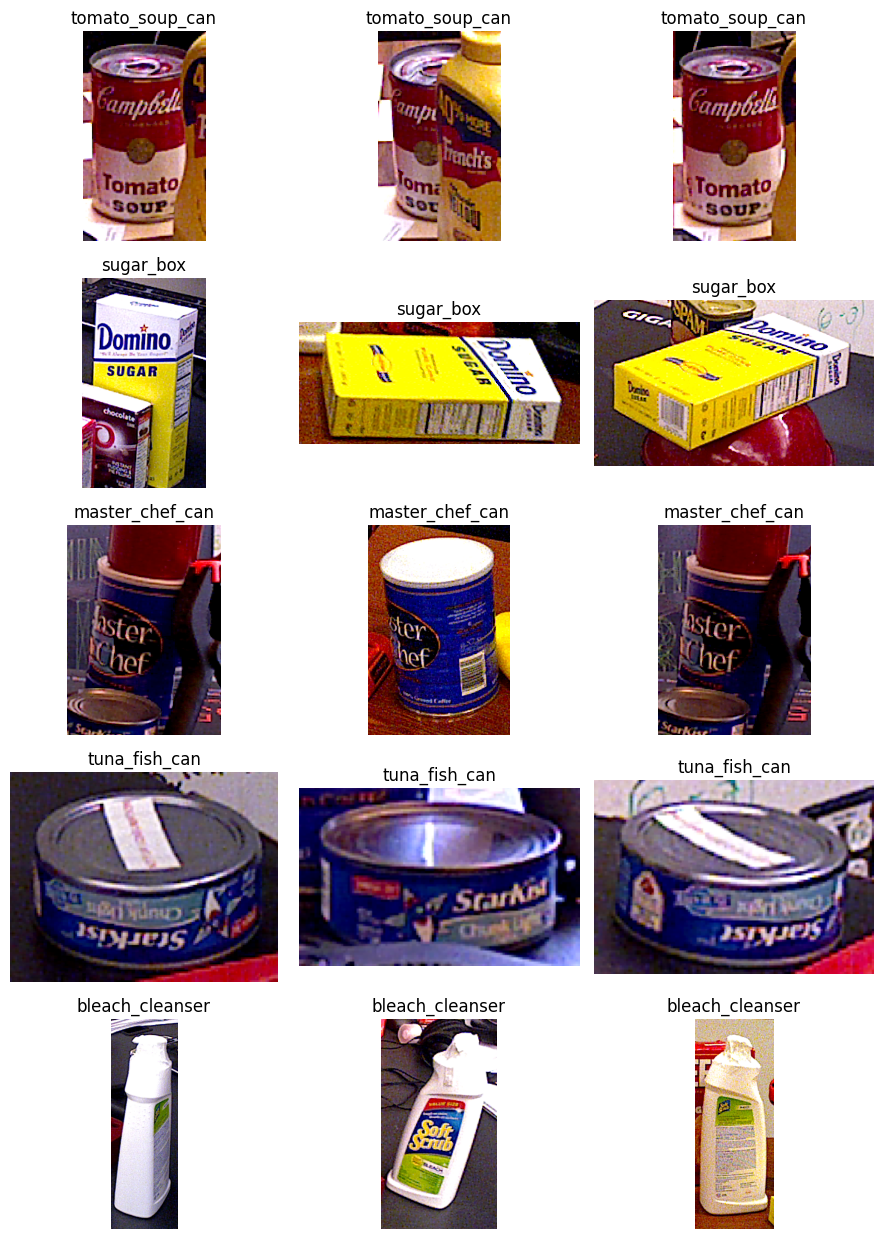

In [9]:
def crop_object(row, padding=0.08):
    image = Image.open(row["rgb_path"]).convert("RGB")
    W, H = image.size

    x, y, w, h = int(row["x"]), int(row["y"]), int(row["w"]), int(row["h"])
    pad_x = int(w * padding)
    pad_y = int(h * padding)

    left = max(0, x - pad_x)
    top = max(0, y - pad_y)
    right = min(W, x + w + pad_x)
    bottom = min(H, y + h + pad_y)

    return image.crop((left, top, right, bottom))

fig, axes = plt.subplots(N_CLASSES, 3, figsize=(9, 2.5 * N_CLASSES))

for r, obj_id in enumerate(SELECTED_OBJ_IDS):
    examples = train_df[train_df["obj_id"] == obj_id].head(3)
    for c, (_, row) in enumerate(examples.iterrows()):
        axes[r, c].imshow(crop_object(row))
        axes[r, c].set_title(row["class_name"])
        axes[r, c].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_crops.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. PyTorch dataset and loaders

Each object crop is:

1. resized to `64×64`,
2. converted to a tensor,
3. normalized to roughly `[-1, 1]`.

No random augmentation is applied in Week 3.

In [10]:
label_map = {obj_id: i for i, obj_id in enumerate(SELECTED_OBJ_IDS)}
inverse_label_map = {i: obj_id for obj_id, i in label_map.items()}
class_names = [YCBV_OBJECTS[obj_id] for obj_id in SELECTED_OBJ_IDS]

base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

class YCBVCropDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        crop = crop_object(row)
        x = self.transform(crop)
        y = label_map[int(row["obj_id"])]
        return x, y

train_ds = YCBVCropDataset(train_df, base_transform)
val_ds = YCBVCropDataset(val_df, base_transform)
test_ds = YCBVCropDataset(test_df, base_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

x_batch, y_batch = next(iter(train_loader))
print("Image batch:", x_batch.shape)
print("Label batch:", y_batch.shape)

Image batch: torch.Size([64, 3, 64, 64])
Label batch: torch.Size([64])


## 10. Baseline MLP

This is a deliberately simple neural-network baseline:

`RGB crop → flatten → Linear → ReLU → Linear → ReLU → class scores`

It has **no CNN, dropout, batch normalization, augmentation, or weight decay**.  
That gives Week 4 a clean baseline to improve.

In [11]:
class BaselineMLP(nn.Module):
    def __init__(self, image_size, n_classes):
        super().__init__()
        input_dim = 3 * image_size * image_size

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        return self.net(x)

model = BaselineMLP(IMAGE_SIZE, N_CLASSES).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {n_params:,}")

BaselineMLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12288, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=5, bias=True)
  )
)
Trainable parameters: 3,179,525


## 11. Training setup

Week 3 uses one fixed setup:

- Loss: CrossEntropyLoss
- Optimizer: Adam
- Learning rate: `1e-3`
- Epochs: `12`

The checkpoint with the best validation loss is saved.

In [12]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

def run_epoch(model, loader, training):
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        if training:
            optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)

        if training:
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(dim=1) == y).sum().item()
        total += y.size(0)

    return total_loss / total, correct / total

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
}

best_val_loss = float("inf")
best_path = OUTPUT_DIR / "best_baseline_mlp.pt"

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(model, train_loader, training=True)
    val_loss, val_acc = run_epoch(model, val_loader, training=False)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_path)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f} acc {train_acc:.3f} | "
        f"val loss {val_loss:.4f} acc {val_acc:.3f}"
    )

print("Best checkpoint:", best_path)

Epoch 01/12 | train loss 0.2222 acc 0.910 | val loss 0.0854 acc 0.971
Epoch 02/12 | train loss 0.0078 acc 0.999 | val loss 0.0516 acc 0.981
Epoch 03/12 | train loss 0.0000 acc 1.000 | val loss 0.0897 acc 0.968
Epoch 04/12 | train loss 0.0001 acc 1.000 | val loss 0.0801 acc 0.968
Epoch 05/12 | train loss 0.0000 acc 1.000 | val loss 0.0709 acc 0.971
Epoch 06/12 | train loss 0.0000 acc 1.000 | val loss 0.0686 acc 0.971
Epoch 07/12 | train loss 0.0000 acc 1.000 | val loss 0.0679 acc 0.971
Epoch 08/12 | train loss 0.0000 acc 1.000 | val loss 0.0677 acc 0.973
Epoch 09/12 | train loss 0.0000 acc 1.000 | val loss 0.0674 acc 0.973
Epoch 10/12 | train loss 0.0000 acc 1.000 | val loss 0.0673 acc 0.973
Epoch 11/12 | train loss 0.0000 acc 1.000 | val loss 0.0672 acc 0.976
Epoch 12/12 | train loss 0.0000 acc 1.000 | val loss 0.0671 acc 0.976
Best checkpoint: outputs/week03/best_baseline_mlp.pt


## 12. Training curves

The important Week 3 question is not only “what accuracy did I get?” but also:

- does training improve?
- does validation improve with it?
- is there an early sign of overfitting?

These curves will become the baseline for Week 4.

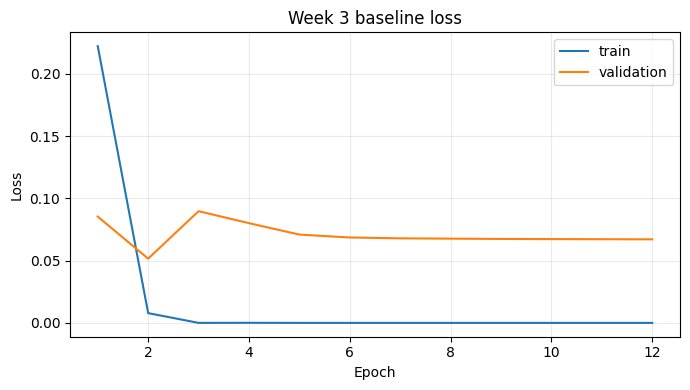

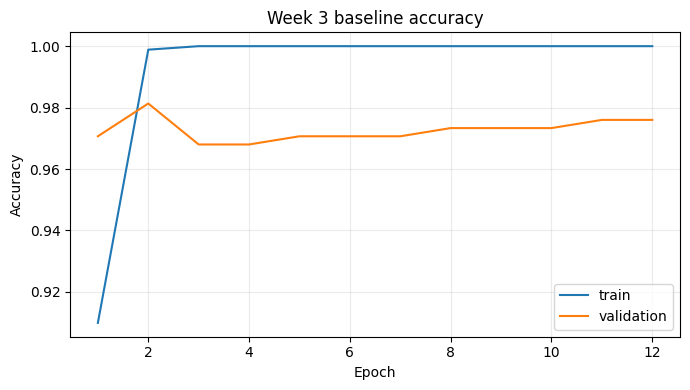

In [13]:
epochs = np.arange(1, EPOCHS + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, history["train_loss"], label="train")
ax.plot(epochs, history["val_loss"], label="validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Week 3 baseline loss")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, history["train_acc"], label="train")
ax.plot(epochs, history["val_acc"], label="validation")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Week 3 baseline accuracy")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "accuracy_curve.png", dpi=160, bbox_inches="tight")
plt.show()

## 13. Test evaluation

The test set is used only after model selection is complete.

Outputs:

- overall test accuracy,
- per-class precision / recall / F1,
- confusion matrix,
- CSV predictions.

In [14]:
model.load_state_dict(torch.load(best_path, map_location=DEVICE))
model.eval()

all_true = []
all_pred = []
all_conf = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        logits = model(x)
        probs = torch.softmax(logits, dim=1)

        pred = probs.argmax(dim=1).cpu().numpy()
        conf = probs.max(dim=1).values.cpu().numpy()

        all_true.extend(y.numpy().tolist())
        all_pred.extend(pred.tolist())
        all_conf.extend(conf.tolist())

test_accuracy = accuracy_score(all_true, all_pred)
report_dict = classification_report(
    all_true,
    all_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(
    all_true,
    all_pred,
    target_names=class_names,
    zero_division=0,
))

metrics = {
    "selected_obj_ids": SELECTED_OBJ_IDS,
    "selected_class_names": class_names,
    "train_samples": len(train_df),
    "val_samples": len(val_df),
    "test_samples": len(test_df),
    "train_scenes": int(train_df["scene_id"].nunique()),
    "val_scenes": int(val_df["scene_id"].nunique()),
    "test_scenes": int(test_df["scene_id"].nunique()),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "best_val_loss": float(best_val_loss),
    "best_val_accuracy": float(max(history["val_acc"])),
    "test_accuracy": float(test_accuracy),
    "classification_report": report_dict,
}

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

pred_df = test_df.copy().reset_index(drop=True)
pred_df["true_label"] = all_true
pred_df["pred_label"] = all_pred
pred_df["pred_class"] = [class_names[i] for i in all_pred]
pred_df["confidence"] = all_conf
pred_df["correct"] = pred_df["true_label"] == pred_df["pred_label"]
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

Test accuracy: 0.5133
                 precision    recall  f1-score   support

tomato_soup_can       0.55      0.47      0.51       150
      sugar_box       0.67      0.39      0.49        75
master_chef_can       0.90      1.00      0.95        75
  tuna_fish_can       0.51      0.60      0.55        75
bleach_cleanser       0.10      0.15      0.12        75

       accuracy                           0.51       450
      macro avg       0.55      0.52      0.52       450
   weighted avg       0.55      0.51      0.52       450



## 14. Confusion matrix

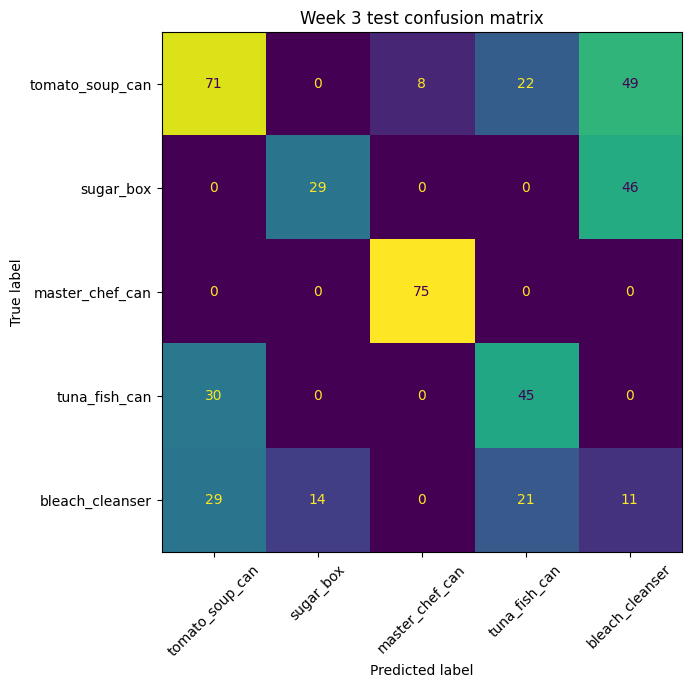

In [15]:
cm = confusion_matrix(all_true, all_pred, labels=list(range(N_CLASSES)))

fig, ax = plt.subplots(figsize=(7, 7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title("Week 3 test confusion matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 15. Correct and wrong predictions

These examples are useful for the report and prepare the error-analysis mindset needed later in the program.

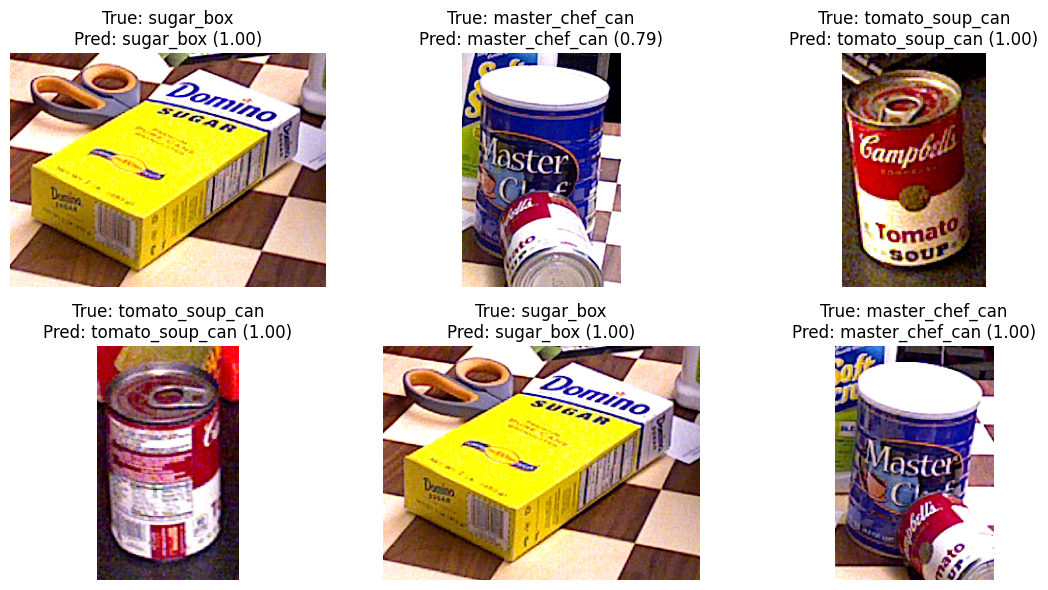

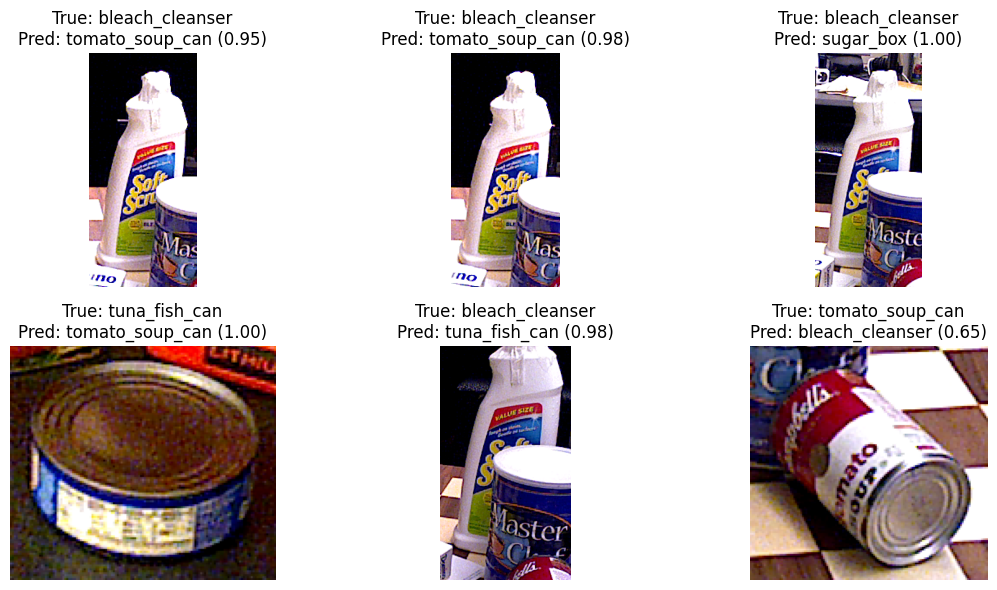

In [16]:
def denormalize(t):
    return (t * 0.5 + 0.5).clamp(0, 1)

def show_prediction_examples(dataset, pred_df, correct_value, n=6, filename="examples.png"):
    candidates = pred_df[pred_df["correct"] == correct_value]
    if len(candidates) == 0:
        print("No samples available for:", correct_value)
        return

    sample = candidates.head(n)
    fig, axes = plt.subplots(2, math.ceil(n / 2), figsize=(12, 6))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (idx, row) in zip(axes, sample.iterrows()):
        crop = crop_object(row)
        ax.imshow(crop)
        ax.set_title(
            f"True: {row['class_name']}\n"
            f"Pred: {row['pred_class']} ({row['confidence']:.2f})"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

show_prediction_examples(
    test_ds,
    pred_df,
    True,
    n=6,
    filename="correct_predictions.png"
)

show_prediction_examples(
    test_ds,
    pred_df,
    False,
    n=6,
    filename="wrong_predictions.png"
)

## 16. Week 3 results to copy into the report

Run this cell last. It prints the exact values you should copy into the DOCX report.

In [17]:
best_epoch = int(np.argmin(history["val_loss"]) + 1)

print("=== WEEK 3 REPORT VALUES ===")
print("Selected classes:", ", ".join(class_names))
print("Train samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))
print("Train scenes:", train_df["scene_id"].nunique())
print("Validation scenes:", val_df["scene_id"].nunique())
print("Test scenes:", test_df["scene_id"].nunique())
print("Best epoch:", best_epoch)
print(f"Best validation loss: {min(history['val_loss']):.4f}")
print(f"Best validation accuracy: {max(history['val_acc']):.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("Trainable parameters:", n_params)
print("Outputs:", OUTPUT_DIR.resolve())

=== WEEK 3 REPORT VALUES ===
Selected classes: tomato_soup_can, sugar_box, master_chef_can, tuna_fish_can, bleach_cleanser
Train samples: 877
Validation samples: 375
Test samples: 450
Train scenes: 8
Validation scenes: 2
Test scenes: 2
Best epoch: 2
Best validation loss: 0.0516
Best validation accuracy: 0.9813
Test accuracy: 0.5133
Trainable parameters: 3179525
Outputs: /content/outputs/week03
